
# **CSCI 5612-872: Machine Learning for DTSC**
##### **Project Topic :** Wine Quality Prediction
##### **Student Name :** Dnyanada Bhosale
##### **Dataset URL :** https://archive.ics.uci.edu/dataset/186/wine+quality
##### **API URL (Grapeminds):**  "https://api.grapeminds.eu/public/v1"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [3]:
df1=pd.read_csv('winequality-red.csv', sep=';')
df1.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
df2=pd.read_csv('winequality-white.csv',sep=';')
df2.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:
df1['type'] = 'red'
df2['type'] = 'white'

df3 = pd.concat([df1, df2], ignore_index=True)
df3.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [6]:
df3.to_csv('winequality_merged.csv', index=False)
df_final= pd.read_csv('winequality_merged.csv')
df_final.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


#### Data collection using API from Grapeminds-api.

In [ ]:
import requests

# Define API Key and Base URL
API_KEY = 'GMOVLPNQQZLX-IoMM0niKLdGD4S8Tx3b5SLDvEcjxQhl8uS9ZWTUkOR26R8wU'
BASE_URL = "https://api.grapeminds.eu/public/v1"

headers = {
    "Authorization": f"Bearer {API_KEY}",
    "Accept": "application/json"
}

ping_response = requests.get(f"{BASE_URL}/ping", headers=headers)
print("Ping Status Code:", ping_response.status_code)
print("Ping Response:", ping_response.json())


wines_response = requests.get(f"{BASE_URL}/wines", headers=headers)

if wines_response.status_code == 200:
    wine_data = wines_response.json()
    print("Successfully retrieved wine data!")
    print(wine_data)
else:
    print(f"Error {wines_response.status_code}:", wines_response.text)

Ping Status Code: 200
Ping Response: {'message': 'API authentication successful', 'authenticated_as': {'user_id': 1028, 'user_name': 'Dnyanada Bhosale', 'user_email': 'dnyanabhosale1207@gmail.com'}, 'api_key': {'name': 'ML_project', 'prefix': 'GMOVLPNQQZLX', 'abilities': ['*'], 'rate_limit_per_minute': 60}, 'timestamp': '2026-09-07T03:17:28+02:00'}
Successfully retrieved wine data!
{'data': [{'id': 1, 'lwin': '1000001', 'display_name': 'Schieferkopf, Lieu Dit Buehl Riesling', 'color': 'white', 'type': 'wine', 'sub_type': 'still', 'residual_sugar': None, 'producer': {'id': 1, 'name': 'Schieferkopf', 'title': None, 'display_name': 'Schieferkopf'}, 'region': {'id': 1, 'name': 'Alsace', 'country': 'fr', 'language': 'en'}}, {'id': 2, 'lwin': '1000014', 'display_name': 'Schieferkopf, Riesling Grand Cru, Kastelberg', 'color': 'white', 'type': 'wine', 'sub_type': 'still', 'residual_sugar': None, 'producer': {'id': 1, 'name': 'Schieferkopf', 'title': None, 'display_name': 'Schieferkopf'}, 'regi

In [ ]:
import json

wines_list = wine_data.get('data', [])
df_api = pd.json_normalize(wines_list)
print(df_api.head())
df_api.to_json('grapeminds_wines.json', orient='records', indent=4)
print("API response successfully converted and saved to grapeminds_wines.json!")

   id     lwin                                       display_name  color  \
0   1  1000001              Schieferkopf, Lieu Dit Buehl Riesling  white   
1   2  1000014       Schieferkopf, Riesling Grand Cru, Kastelberg  white   
2   3  1000027                           Schieferkopf, Pinot Gris  white   
3   4  1000030  Schieferkopf, Riesling Grand Cru, Altenberg de...  white   
4   5  1000043                             Schieferkopf, Sylvaner  white   

   type sub_type residual_sugar  producer.id producer.name producer.title  \
0  wine    still           None            1  Schieferkopf           None   
1  wine    still           None            1  Schieferkopf           None   
2  wine    still           None            1  Schieferkopf           None   
3  wine    still           None            1  Schieferkopf           None   
4  wine    still           None            1  Schieferkopf           None   

  producer.display_name  region.id            region.name region.country  \
0   

##### I completed the GrapeMinds API integration by pulling the data and saving it to a JSON file as required. However, that data only has metadata like producer names and regions, not chemical data. Since this assignment requires analyzing wine properties, I am using the merged UCI Wine Quality dataset instead. It includes all the chemical features I need for my analysis—such as acidity, sugar, pH, alcohol, and quality ratings.


#### Exploratory Data Analysis (EDA)

In [7]:
df_final.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [8]:
for col in df_final.columns:
  if df_final[col].isnull().sum() > 0:
    df_final[col] = df_final[col].fillna(df_final[col].mean())

df_final.isnull().sum().sum()

np.int64(0)

In [9]:
df_final.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


In [10]:

print(f"Duplicate rows before: {df_final.duplicated().sum()}")
df_final.drop_duplicates (inplace=True)
print(f"Duplicate rows after cleaning:",df_final.duplicated().sum() )


Duplicate rows before: 1177
Duplicate rows after cleaning: 0


In [11]:
if 'type' in df_final.columns:
    # Binary encoding: red -> 0, white -> 1
    df_final['type_encoded'] = (df_final['type'] == 'white').astype(int)
    df_final = df_final.drop(columns=['type'])
df_final.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_encoded
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [12]:
# Continuous chemical features for capping
continuous_cols = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
    'density', 'pH', 'sulphates', 'alcohol'
]

# Cap outliers to upper and lower IQR bounds
for col in continuous_cols:
    Q1 = df_final[col].quantile(0.25)
    Q3 = df_final[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_final[col] = np.clip(df_final[col], lower_bound, upper_bound)
df_final.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_encoded
0,7.40,0.68,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.80,0.68,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.80,0.68,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,9.65,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
5,7.40,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [13]:
# Binary target: 0 = Low/Medium Quality (<= 6), 1 = High Quality (>= 7)
df_final['quality_class'] = (df_final['quality'] >= 7).astype(int)

print(df_final['quality_class'].value_counts())

quality_class
0    4311
1    1009
Name: count, dtype: int64


In [14]:
#Cleaned data
df_final.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type_encoded,quality_class
0,7.40,0.68,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.80,0.68,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0,0
2,7.80,0.68,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0,0
3,9.65,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0,0
5,7.40,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0,0
6,7.90,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5,0,0
7,7.30,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7,0,1
8,7.80,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7,0,1
9,7.50,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5,0,0
10,6.70,0.58,0.08,1.8,0.097,15.0,65.0,0.9959,3.28,0.54,9.2,5,0,0


#### Data Visualizations

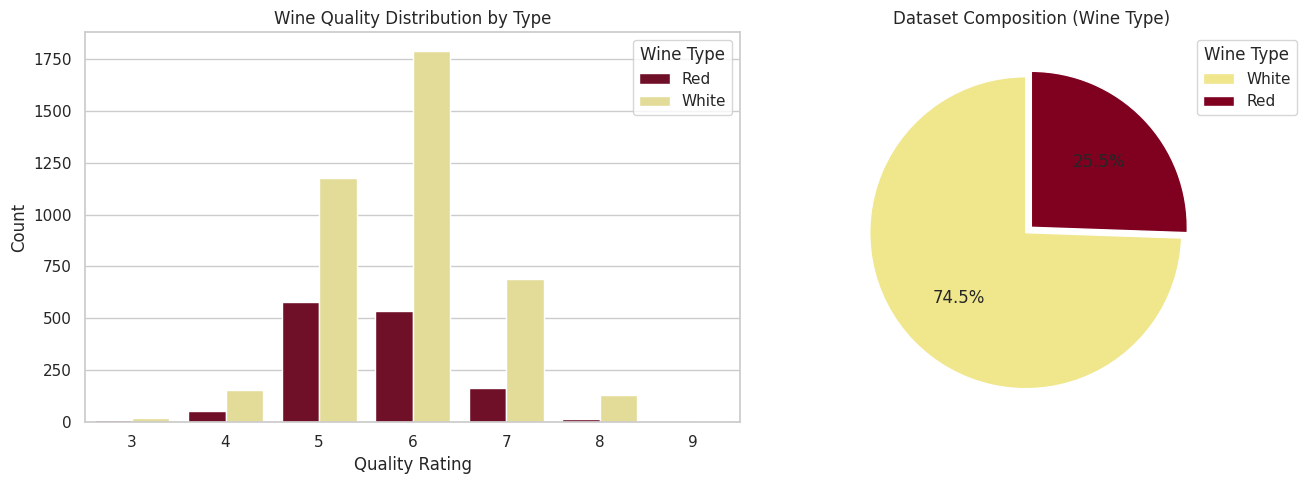

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1.Distribution of Wine Quality across Wine Types
sns.countplot(data=df_final, x='quality', hue='type_encoded', palette=['#800020', '#F0E68C'], ax=axes[0])
axes[0].set_title('Wine Quality Distribution by Type')
axes[0].set_xlabel('Quality Rating')
axes[0].set_ylabel('Count')
handles, labels = axes[0].get_legend_handles_labels()
hue_labels_map = {'0': 'Red', '1': 'White'}
axes[0].legend(handles=handles, labels=[hue_labels_map[label] for label in labels], title="Wine Type")


# 2.Proportion of Red vs. White Wine
type_counts = df_final['type_encoded'].value_counts()
pie_labels_map = {0: 'Red', 1: 'White'}
labels_for_pie_legend = [pie_labels_map[idx] for idx in type_counts.index]
colors_for_pie = ['#F0E68C' if idx == 1 else '#800020' for idx in type_counts.index] # White gets yellow, Red gets maroon


type_counts.plot.pie(
    autopct='%1.1f%%',
    colors=colors_for_pie,
    ax=axes[1],
    startangle=90,
    explode=(0.05, 0),
    labels=['', '']
)


wedges = axes[1].patches

axes[1].set_title('Dataset Composition (Wine Type)')
axes[1].set_ylabel('')

axes[1].legend(
    wedges, labels_for_pie_legend,
    title="Wine Type",
    loc="upper right",
    bbox_to_anchor=(1.2, 1)
)

plt.tight_layout()
plt.show()

##### The countplot wine quality distribution suggests that white wine has high quality rating as compared to red wine. Quality rating for 6 (White wine) is highest among all.

##### The pie chart suggests that white wine contributes to 74.5% of the dataset composition which is majority of the data.


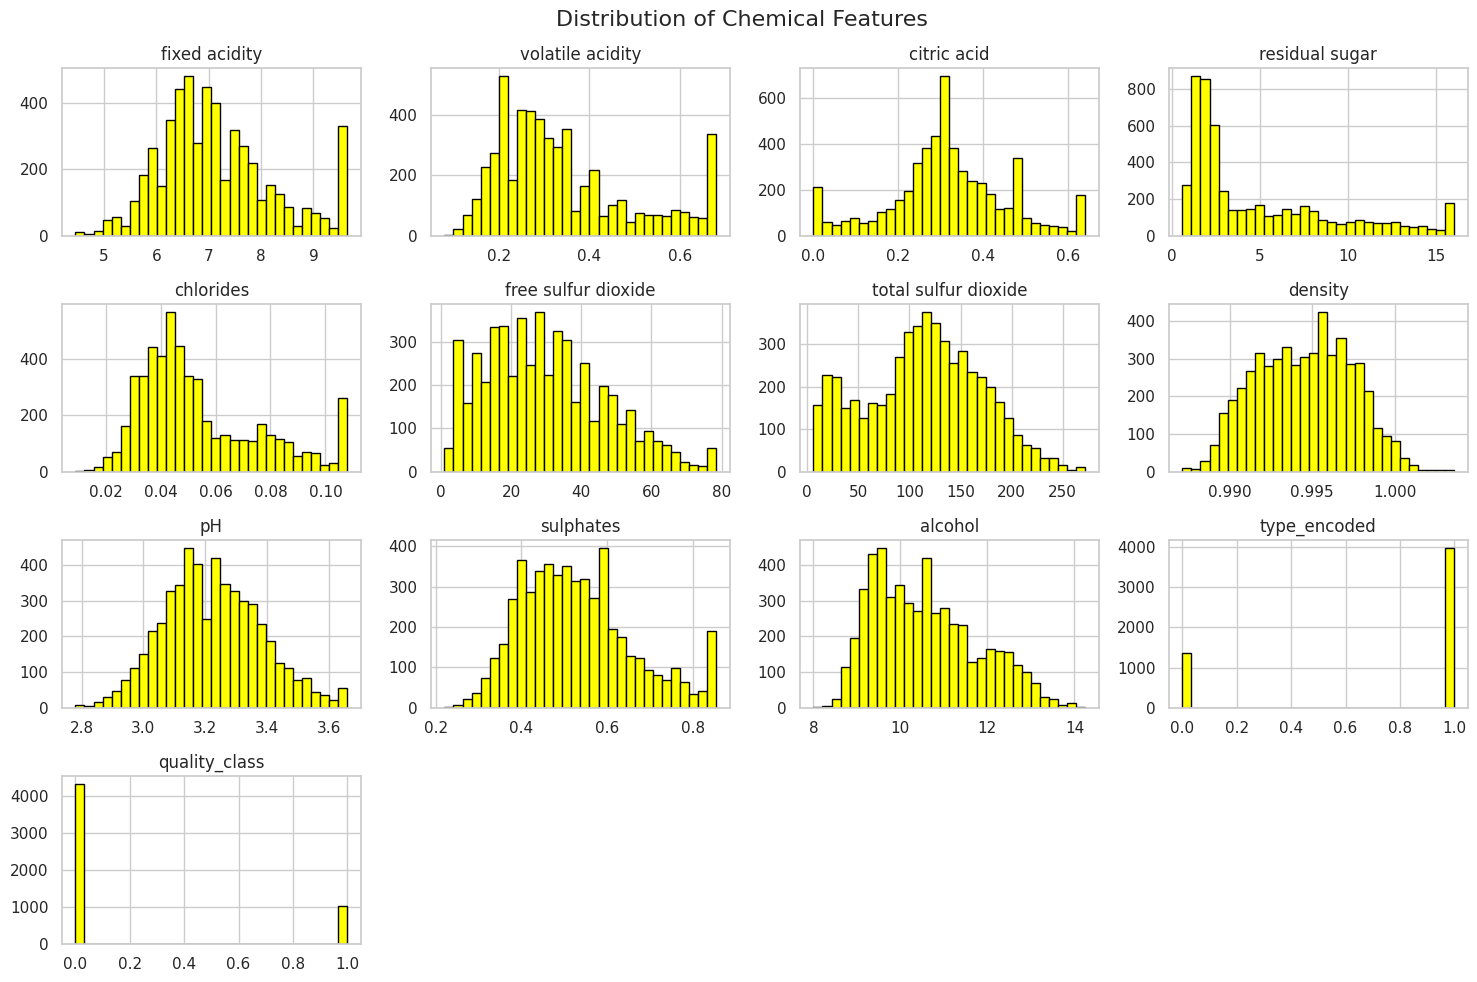

In [ ]:
# 3.Feature Distribution Histogram
features = [col for col in df_final.columns if col not in ['quality', 'type']]

df_final[features].hist(bins=30, figsize=(15, 10), color='yellow', edgecolor='black')
plt.suptitle('Distribution of Chemical Features', fontsize=16)
plt.tight_layout()
plt.show()

##### This multi-panel histogram visualizes the distribution of 11 continuous chemical features from the wine dataset. While features like pH, fixed acidity, and density exhibit roughly bell-shaped (normal) distributions, features such as residual sugar, chlorides, volatile acidity, and sulphates show heavy right-skewness with long upper tails. Additionally, total sulfur dioxide displays a slight bimodal tendency, while alcohol presents an irregular, multi-peaked right-skewed profile.

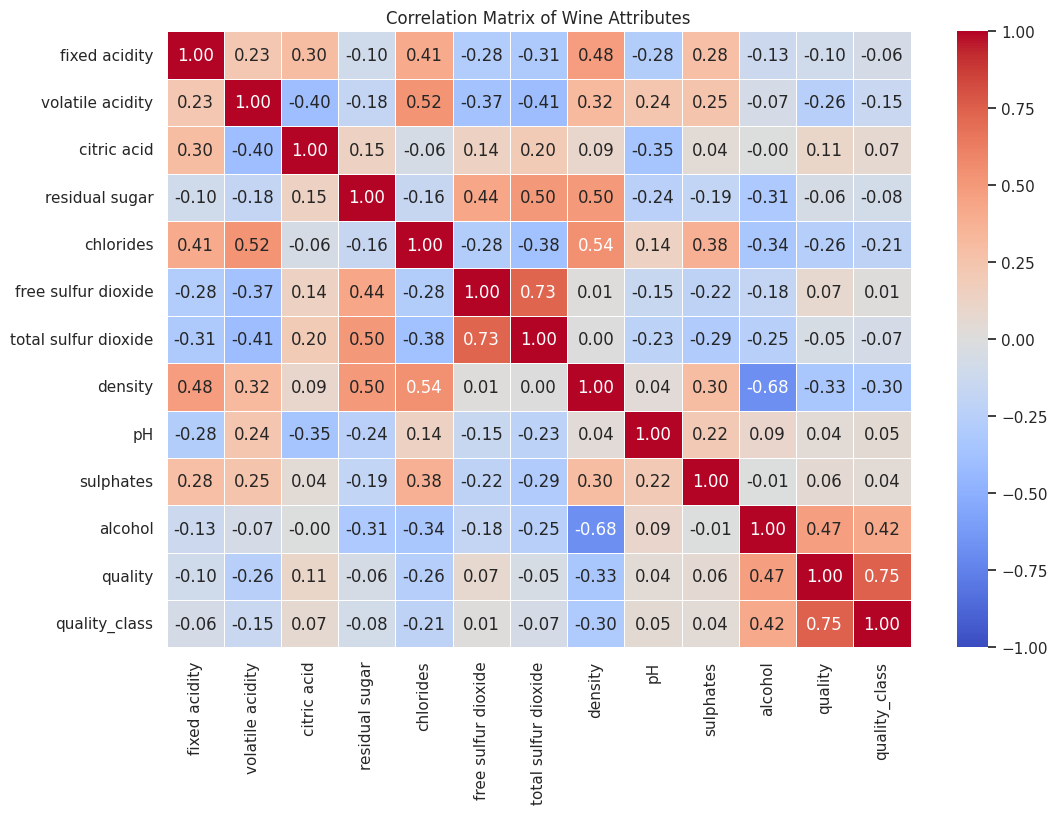

In [ ]:
# 4. Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_df = df_final.drop(columns=['type_encoded'])
correlation_matrix = numeric_df.corr()

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Wine Attributes')
plt.show()

##### Citric acid and alcohol are least correlated to each other. Their correlation coefficient is -0.00.Total sulfur dioxide and free sulfur dioxide are highly correlated,show a linear relationship with each other and their correlation coefficient is 0.73.

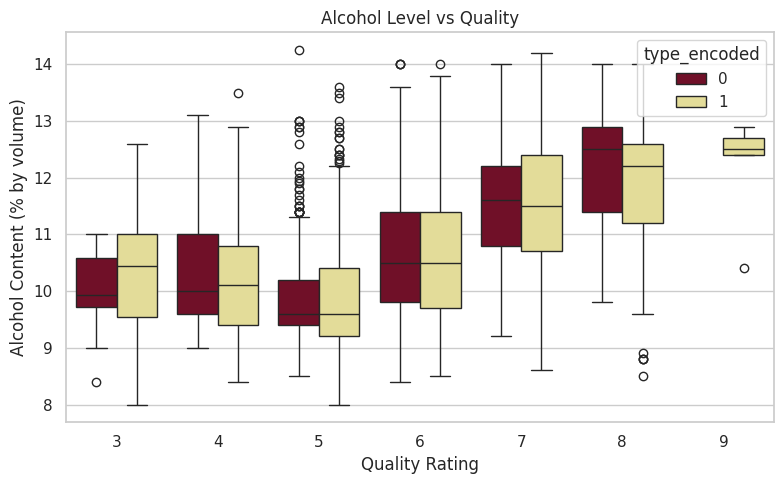

In [ ]:
# 5. Boxplot of Alcohol vs Quality
plt.figure(figsize=(8, 5))
ax = sns.boxplot(data=df_final, x='quality', y='alcohol', hue='type_encoded', palette=['#800020', '#F0E68C'])
plt.title('Alcohol Level vs Quality')
plt.xlabel('Quality Rating')
plt.ylabel('Alcohol Content (% by volume)')
plt.tight_layout()
plt.show()

##### The boxplot of quality rating 5 has highest number of outliers. It also has smallest median value as compared to other Quality rating.The boxplot shows a clear positive correlation between alcohol content and wine quality rating across both red and white wines, particularly for quality rating from 5 to 9.

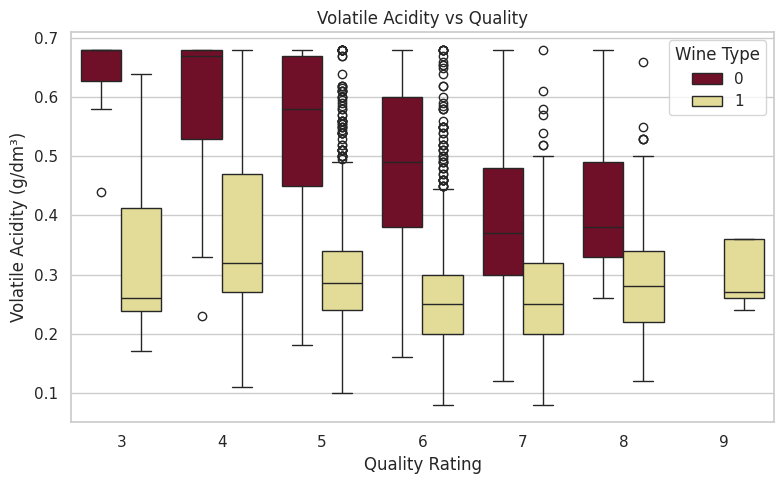

In [ ]:
# 6. Boxplot of Volatile Acidity vs Quality
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_final, x='quality', y='volatile acidity', hue='type_encoded', palette=['#800020', '#F0E68C'])
plt.title('Volatile Acidity vs Quality')
plt.xlabel('Quality Rating')
plt.ylabel('Volatile Acidity (g/dm³)')
plt.legend(title='Wine Type')
plt.tight_layout()
plt.show()

##### Quality score 5 contains the heaviest concentration of upper outliers.Quality rating 9 is exclusive to white wine, with a narrow interquartile range (IQR). Red wines consistently exhibit significantly higher volatile acidity levels than white wines across every single quality rating.

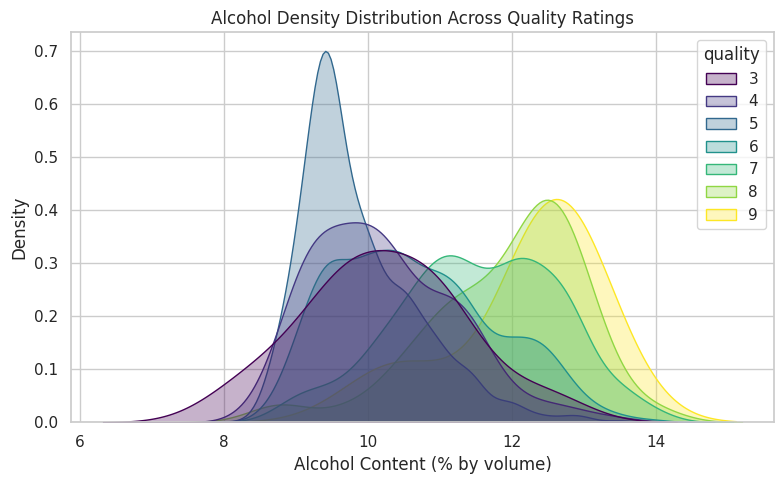

In [ ]:
# 7. Density Plot: Distribution of Alcohol Content by Quality
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_final, x='alcohol', hue='quality', palette='viridis', common_norm=False, fill=True, alpha=0.3)
plt.title('Alcohol Density Distribution Across Quality Ratings')
plt.xlabel('Alcohol Content (% by volume)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

##### As quality ratings increase from 5 to 9, the probability density curves shift distinctly to the right, indicating that higher-rated wines consistently contain higher alcohol percentages. Quality score 5 exhibits a tall, narrow peak centered around ~9.5% alcohol, reaching a density over 0.7. This reflects a highly concentrated sample volume around lower alcohol levels.

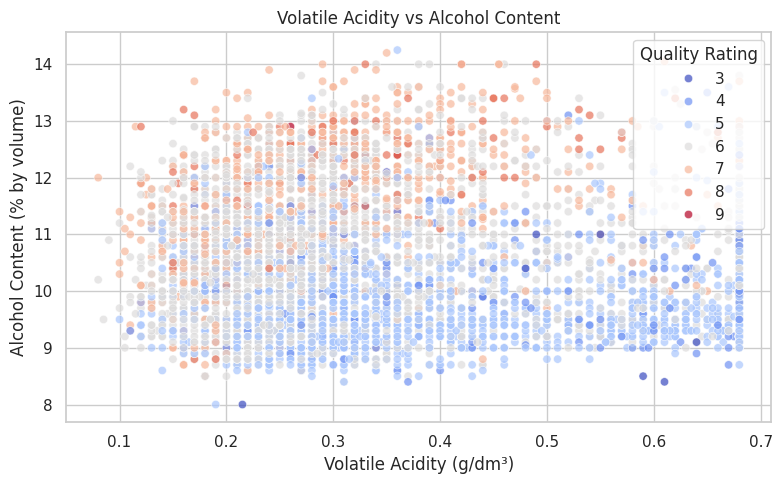

In [ ]:
# 8. Pairwise Scatter Plot: Volatile Acidity vs Alcohol colored by Quality
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_final, x='volatile acidity', y='alcohol', hue='quality', palette='coolwarm', alpha=0.7)
plt.title('Volatile Acidity vs Alcohol Content')
plt.xlabel('Volatile Acidity (g/dm³)')
plt.ylabel('Alcohol Content (% by volume)')
plt.legend(title='Quality Rating')
plt.tight_layout()
plt.show()

##### High-rated wines (scores 7, 8, and 9 in peach and red) cluster heavily in the upper-left region.This indicates that superior wines combine high alcohol content with low volatile acidity.

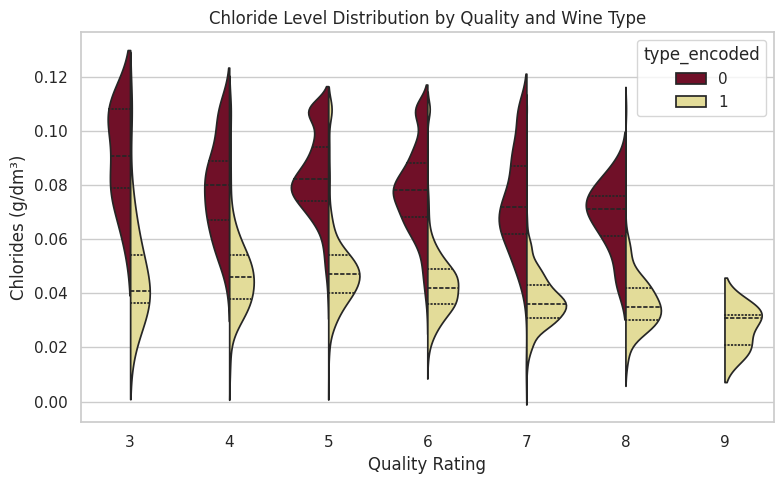

In [ ]:
# 9. Violin Plot: Chloride Levels by Wine Type and Quality
plt.figure(figsize=(8, 5))
sns.violinplot(data=df_final, x='quality', y='chlorides', hue='type_encoded', split=True, palette=['#800020', '#F0E68C'], inner='quartile')
plt.title('Chloride Level Distribution by Quality and Wine Type')
plt.xlabel('Quality Rating')
plt.ylabel('Chlorides (g/dm³)')
plt.tight_layout()
plt.show()

##### For red wine, median chloride levels subtly decline as quality improves from score 5 to score 8. For white wine, chloride levels remain consistently low and tightly bound across every rating.

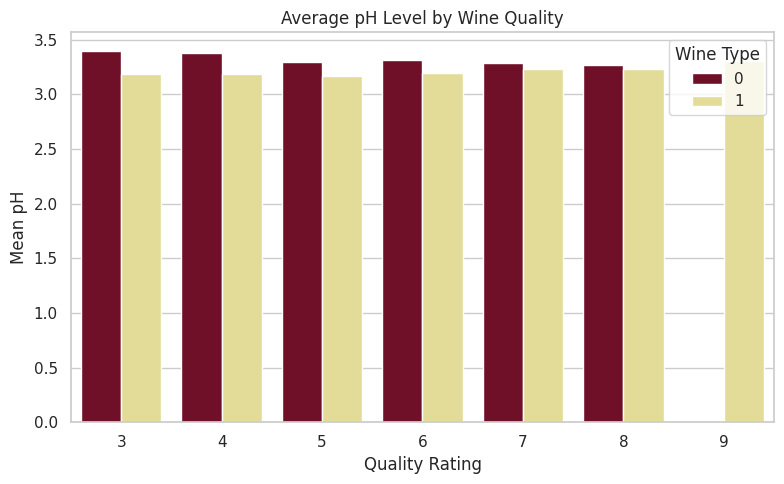

In [ ]:
# 10. Mean pH Level by Wine Quality and Type
plt.figure(figsize=(8, 5))
sns.barplot(data=df_final, x='quality', y='pH', hue='type_encoded', palette=['#800020', '#F0E68C'], errorbar=None)
plt.title('Average pH Level by Wine Quality')
plt.xlabel('Quality Rating')
plt.ylabel('Mean pH')
plt.legend(title='Wine Type')
plt.tight_layout()
plt.show()

##### Grouped bar chart displays the average pH levels across quality ratings (3 through 9) for red and white wines. Average pH levels remain uniform regardless of wine quality, staying tightly bounded between 3.15 and 3.40.

#### Clustering

K-Means Silhouette Evaluation
k = 2 | Silhouette Score: 0.2749
k = 3 | Silhouette Score: 0.2416
k = 4 | Silhouette Score: 0.2427


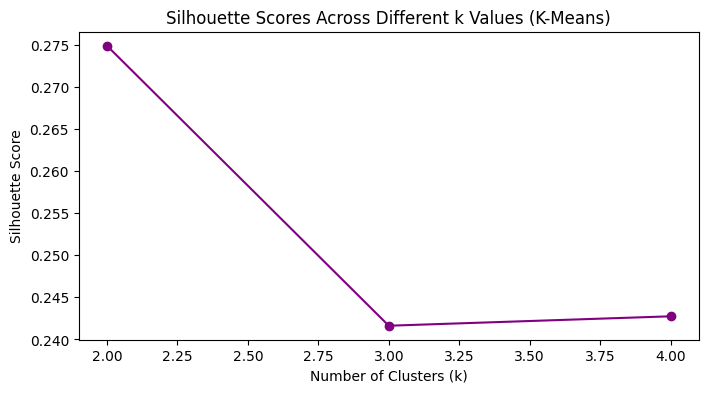


Best k suggested by Silhouette Method: 2



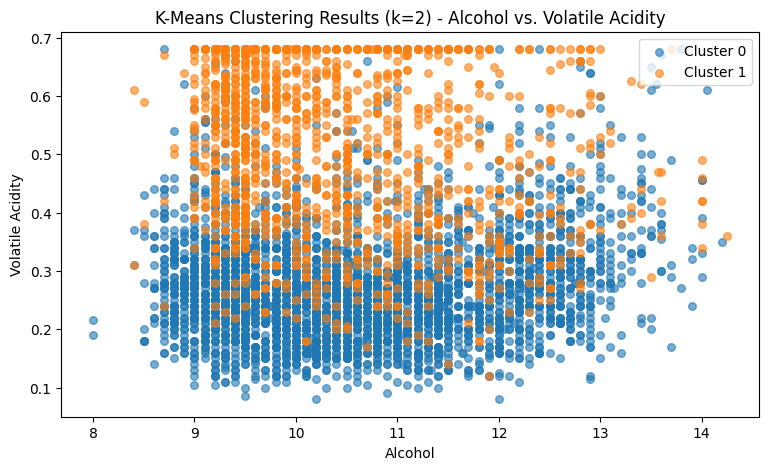

In [ ]:

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

plt.rcParams['axes.grid'] = False
plt.style.use('default')

feature_cols = [
    'fixed acidity',
    'volatile acidity',
    'citric acid',
    'residual sugar',
    'chlorides',
    'free sulfur dioxide',
    'total sulfur dioxide',
    'density',
    'pH',
    'sulphates',
    'alcohol',
]

X = df_final[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = [2, 3, 4]
silhouette_scores = []

print('K-Means Silhouette Evaluation')
for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels)
  silhouette_scores.append(score)
  print(f'k = {k} | Silhouette Score: {score:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker='o', linestyle='-', color='purple')
plt.title('Silhouette Scores Across Different k Values (K-Means)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()

best_k = k_values[np.argmax(silhouette_scores)]
print(f'\nBest k suggested by Silhouette Method: {best_k}\n')

kmeans_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df_final['KMeans_Cluster'] = kmeans_best.fit_predict(X_scaled)

plt.figure(figsize=(9, 5))
for c in range(best_k):
  subset = df_final[df_final['KMeans_Cluster'] == c]
  plt.scatter(
      subset['alcohol'],
      subset['volatile acidity'],
      label=f'Cluster {c}',
      alpha=0.6,
      s=30,
  )
plt.title(
    f'K-Means Clustering Results (k={best_k}) - Alcohol vs. Volatile Acidity'
)
plt.xlabel('Alcohol')
plt.ylabel('Volatile Acidity')
plt.legend(loc='upper right')
plt.show()






##### Three different cluster counts: k = 2, k = 3, and k = 4 were used to examine how the wine dataset partitions across feature space. The Silhouette scores obtained across the evaluated values were:
##### 1) k = 2: 0.2749  , 2) k = 3: 0.2416 , 3)  k = 4: 0.2427

##### The Silhouette method identified k = 2 as the optimal number of clusters, achieving the highest cohesion and separation score among the tested values.  

##### The silhouette line plot and the k = 2 scatter plot of Alcohol vs. Volatile Acidity illustrate the two primary partitions cleanly separating the dataset.


In [ ]:
# A preview of the cleaned numeric feature subset used for clustering and PCA
display(df_final[feature_cols].head(10))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.40,0.68,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.80,0.68,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.80,0.68,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,9.65,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
5,7.40,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4
6,7.90,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4
7,7.30,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0
8,7.80,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5
9,7.50,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5
10,6.70,0.58,0.08,1.8,0.097,15.0,65.0,0.9959,3.28,0.54,9.2


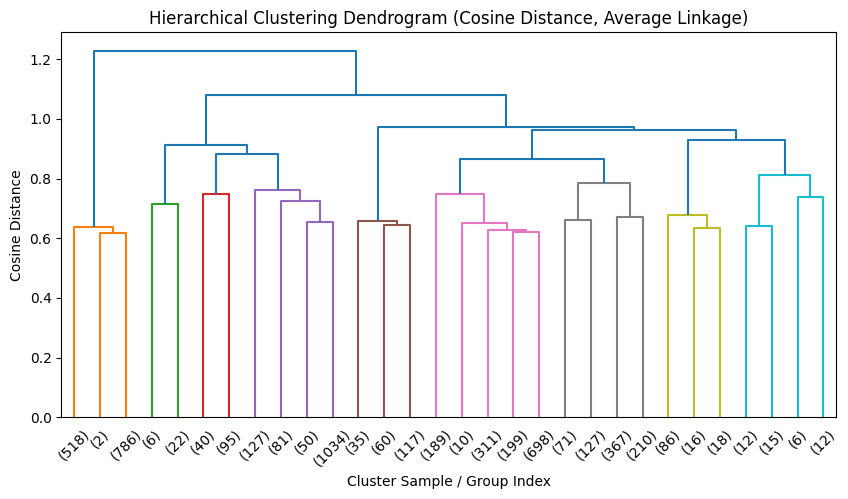

Hierarchical Clustering assignment distribution:
2    4014
1    1306
Name: count, dtype: int64


In [ ]:

plt.rcParams['axes.grid'] = False
plt.style.use('default')

cosine_dist_matrix = pdist(X_scaled, metric='cosine')

linked = linkage(cosine_dist_matrix, method='average')

plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=10)
plt.title(
    'Hierarchical Clustering Dendrogram (Cosine Distance, Average Linkage)'
)
plt.xlabel('Cluster Sample / Group Index')
plt.ylabel('Cosine Distance')
plt.show()

hclust_labels = fcluster(linked, t=best_k, criterion='maxclust')
df_final['HClust_Cluster'] = hclust_labels

print('Hierarchical Clustering assignment distribution:')
print(pd.Series(hclust_labels).value_counts())





#####  Hierarchical agglomerative clustering was performed using Cosine distance (Distance = 1 - Cosine Similarity) with average linkage. Cosine distance evaluates the directional angles of chemical features rather than absolute magnitudes, making it effective for relative proportion matching in wine profiles.

##### Cutting the hierarchical tree at k = 2 yields an assignment distribution of 4,014 samples in one cluster and 1,306 samples in the other.  

##### Both K-Means (silhouette scores) and hierarchical clustering (guided by dendrogram height thresholds) independently converge on k = 2 as the most natural structural division for the wine dataset.

##### The partition sizes from K-Means and hierarchical clustering closely mirror each other, capturing the primary underlying macro-structure (such as broad chemical profile variations) within the merged wine dataset.

##### Both techniques group wine samples based on continuous chemical properties (such as volatile acidity, residual sugar, density, and alcohol). While K-means is efficient for large datasets, hierarchical clustering provides deeper insight into data structure and cluster relationships without requiring an upfront assumption of spherical cluster shapes. By analyzing the linkage distance and vertical jump heights on the dendrogram, hierarchical clustering strongly suggests k = 2.

# **Key Conclusions from the Clustering Analysis**

####**Model Comparison:**  While K-Means effectively partitions data into predefined groups, hierarchical clustering provides deeper insights into the underlying data structure through dendrograms.

####**Optimal Clusters (k = 2):**  The analysis suggests an optimal k = 2 for the wine data, which successfully captures the primary chemical divergence between red and white wine profiles.

####**Unsupervised Discovery:**   Unsupervised methods uncover natural groupings based on physicochemical features without being influenced by human-assigned quality bias.

####**Practical Applications:**  Clustering acts as a powerful discovery tool to detect chemical sub-populations, validate label consistency, and identify outliers, ultimately enabling automated quality control that reduces sensory evaluation costs.



##### PCA

In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

feature_cols = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
    'density', 'pH', 'sulphates', 'alcohol'
]
X = df_final[feature_cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
df_pca['quality_class'] = df_final['quality_class'].values


print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Explained:", sum(pca.explained_variance_ratio_))
df_pca.head(10) # Screenshot of data after PCA transformation


Explained Variance Ratio: [0.29409533 0.22979215]
Total Variance Explained: 0.5238874801051827


,PC1,PC2,quality_class
0,-3.618121,-0.143577,0
1,-3.350871,0.663794,0
2,-3.561706,0.400079,0
3,-1.853080,1.595203,0
4,-3.459622,-0.120589,0
5,-2.496133,0.012051,0
6,-2.760945,-1.128403,1
7,-3.315498,-0.196661,1
8,-2.150285,0.943491,0
9,-2.711124,0.162813,0


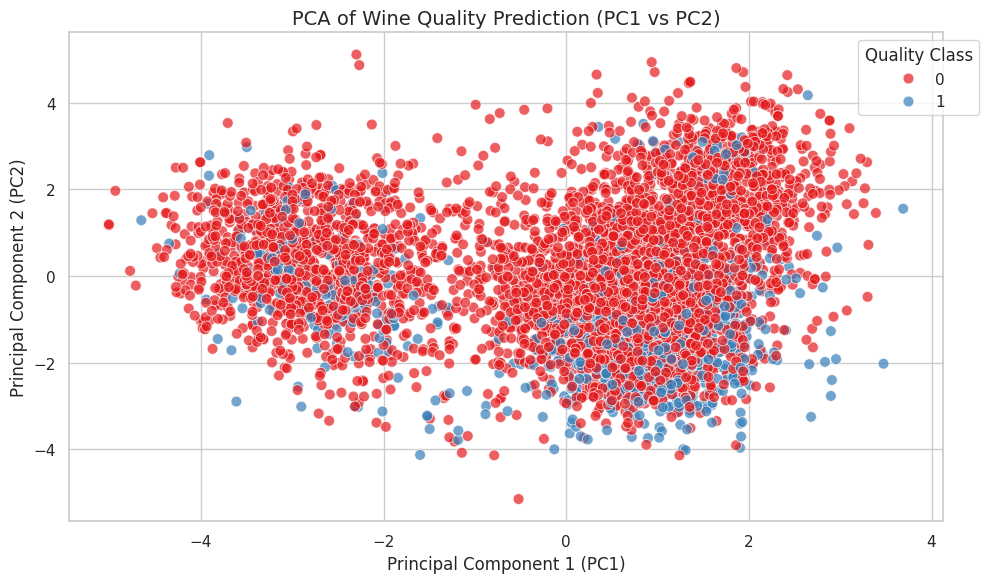

In [18]:

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='quality_class',
    data=df_pca,
    palette='Set1',
    alpha=0.7,
    edgecolor='w',
    s=60
)

plt.title('PCA of Wine Quality Prediction (PC1 vs PC2)', fontsize=14)
plt.xlabel('Principal Component 1 (PC1)', fontsize=12)
plt.ylabel('Principal Component 2 (PC2)', fontsize=12)

plt.legend(title='Quality Class', bbox_to_anchor=(1.05, 1), loc='upper right')
plt.tight_layout()
plt.show()

##### PC1 (x-axis) and PC2 (y-axis) compress the multi-dimensional chemical feature space down to two orthogonal axes, capturing the primary directions of variance across features like acidity, density, alcohol, and sulfur dioxide.The scatter plot shows significant overlap between quality class 0 (red) and quality class 1 (blue).

##### This indicates that linear dimensionality reduction alone (retaining only the top 2 components) does not achieve complete linear separability between high and low-quality wines. Unsupervised PCA maximizes total variance rather than class separation, that means class labels are distributed across the entire projection space.

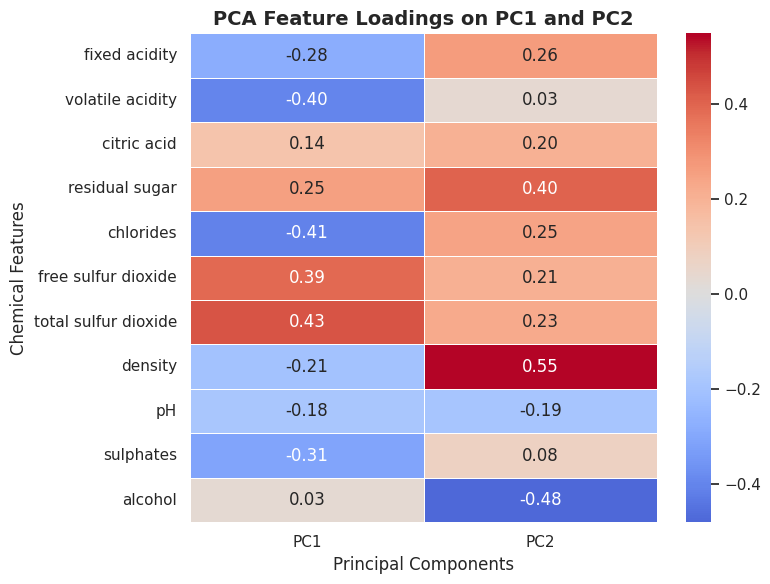

In [ ]:

loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=feature_cols
)

plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=0.5)
plt.title('PCA Feature Loadings on PC1 and PC2', fontsize=14, weight='bold')
plt.xlabel('Principal Components', fontsize=12)
plt.ylabel('Chemical Features', fontsize=12)
plt.tight_layout()
plt.show()

##### Component Loadings (the eigenvectors scaled by the square root of the eigenvalues), which represent the correlation and weight of each original feature on each component.

##### Component Loadings Heatmap : A loadings heatmap provides a clear, compact view of how heavily each chemical property contributes to PC1 and PC2.

#####  Features with values close to +1 or -1 have a strong influence on that particular principal component. For example, if alcohol and density show high opposing weights on PC1, it tells you that PC1 fundamentally captures the balance between body/alcohol content and physical density.

##### Positive loadings mean the feature increases as the component score increases, while negative loadings indicate an inverse relationship.

##**Key Conclusions & Findings from the PCA Analysis**

Principal Component Analysis was applied to reduce feature space dimensionality and filter noise by transforming correlated chemical attributes into uncorrelated principal components.

**Feature Standardization:** Prior to computing the components, all numeric chemical features were standardized to ensure that attributes with larger numeric scales did not disproportionately skew the variance calculations.

**Variance Capture & Class Separability:** The analysis demonstrated that while PCA successfully captures the primary variance across the chemical properties, it does not achieve complete linear separability between the high and low-quality wine classes.

**Visualizations & Feature Loadings:** Using 2D scatter plots and feature loading heatmaps, the visualizations illustrated how individual chemical properties—such as alcohol content and density—contribute to the overall variance across the principal components.